# Data timing analysis: 58 ms vs 1.54 s OE lung MRI

Goal of this notebook:
1. Read the raw Philips DICOM headers to find the true frame timing and sequence parameters of the fast (58 ms) scans.
2. Plot mean lung intensity over time for the fast registered scan (`data/0601_reg/reg`) and the 1.54 s clinical-protocol scan (`data/TV3_20220208/reg`).
3. Work out which frames were acquired while breathing air vs 100% oxygen.

Conventions: `IM-SS-EE-FFFF` = slice SS, echo EE (01 = TE1 ~0.71 ms, 02 = TE2 ~1.21 ms), frame FFFF. Images are rotated with `np.rot90` for display so that the head is at the top.

In [1]:
import os, glob, datetime as dt
import numpy as np
import pandas as pd
import nibabel as nib
import pydicom
import matplotlib.pyplot as plt
from scipy import ndimage as ndi
from skimage.filters import threshold_otsu

ROOT = r'C:\edshkim98\phd\mina\data'
FAST_DT = 0.058   # s, nominal spacing of the fast scan (verified below)
SLOW_DT = 1.54    # s, spacing of the clinical protocol (Kim et al. 2024)
GAS_SWITCH_SLOW = (60, 210)  # protocol: frames 1-60 air, 61-210 O2, 211-340 air

def load_series(pattern):
    files = sorted(glob.glob(pattern))
    return np.stack([np.rot90(nib.load(f).get_fdata()) for f in files]).astype(np.float32)

## 1. Raw DICOM headers of the fast scans

Two enhanced multi-frame DICOMs exist: `0401/IM_0012` (series "2D AICS3") and `0601/IM_0010` (series "2D AICS3 2nd gas challenge"). Each holds 4000 frames = 2000 dynamics x 2 echoes, interleaved echo1/echo2.

In [2]:
def parse_dt(s):
    s = s.strip()
    if '.' not in s:
        s += '.0'
    return dt.datetime.strptime(s, '%Y%m%d%H%M%S.%f')

def dicom_summary(path):
    ds = pydicom.dcmread(path, stop_before_pixels=True, force=True)
    shared = ds.SharedFunctionalGroupsSequence[0]
    timing = shared.MRTimingAndRelatedParametersSequence[0]
    fov = shared.MRFOVGeometrySequence[0]
    pf = ds.PerFrameFunctionalGroupsSequence
    times = np.array([(parse_dt(f.FrameContentSequence[0].FrameAcquisitionDateTime)) for f in pf])
    tes = np.array([float(f.MREchoSequence[0].EffectiveEchoTime) for f in pf])
    t0 = times[0]
    tsec = np.array([(t - t0).total_seconds() for t in times])
    e1 = tes < 1.0
    info = {
        'file': path.replace(ROOT, ''),
        'series': str(ds.SeriesDescription),
        'scanner': f"{ds.Manufacturer} {ds.ManufacturerModelName} {ds.MagneticFieldStrength}T",
        'date / start time': str(times[0]),
        'end time': str(times[-1]),
        'sequence': 'spoiled gradient echo (M_FFE), 2D single slice',
        'TR (ms)': float(timing.RepetitionTime),
        'TE1 / TE2 (ms)': f"{tes[e1][0]:.3f} / {tes[~e1][0]:.3f}",
        'flip angle (deg)': float(timing.FlipAngle),
        'matrix': f"{fov.MRAcquisitionFrequencyEncodingSteps} x {fov.MRAcquisitionPhaseEncodingStepsInPlane}",
        'pixel (mm)': str(pf[0].PixelMeasuresSequence[0].PixelSpacing),
        'slice thickness (mm)': float(pf[0].PixelMeasuresSequence[0].SliceThickness),
        'acceleration': f"{ds.ParallelAcquisitionTechnique} x{float(ds.ParallelReductionFactorInPlane):.0f}, partial Fourier {shared.MRModifierSequence[0].PartialFourier}",
        'n dynamics (echo1 frames)': int(e1.sum()),
        'acquisition duration (s)': float(ds.AcquisitionDuration),
        'mean frame spacing (ms)': float(np.diff(tsec[e1]).mean() * 1000),
        'spacing values (ms)': str(dict(zip(*np.unique(np.round(np.diff(tsec[e1]) * 1000).astype(int), return_counts=True)))),
    }
    return info, tsec[e1]

info_0401, t_0401 = dicom_summary(os.path.join(ROOT, '0401', 'IM_0012'))
info_0601, t_0601 = dicom_summary(os.path.join(ROOT, '0601', 'IM_0010'))
pd.set_option('display.max_colwidth', 120)
pd.DataFrame([info_0401, info_0601]).T

,0,1
file,\0401\IM_0012,\0601\IM_0010
series,2D AICS3,2D AICS3 2nd gas challenge
scanner,Philips MR 7700 3T,Philips MR 7700 3T
date / start time,2025-01-08 12:10:36.270000,2025-01-08 12:20:32.080000
end time,2025-01-08 12:12:32.250000,2025-01-08 12:22:28.060000
sequence,"spoiled gradient echo (M_FFE), 2D single slice","spoiled gradient echo (M_FFE), 2D single slice"
TR (ms),2.2314,2.2314
TE1 / TE2 (ms),0.710 / 1.207,0.710 / 1.207
flip angle (deg),4.0,4.0
matrix,96 x 96,96 x 96


**Reading the header.** 96 phase-encode lines at TR = 2.23 ms would take 214 ms. With Compressed SENSE x3 and partial Fourier only roughly a quarter of the lines are acquired, which gives the ~58 ms per dynamic. The clinical protocol in the paper used TR = 16 ms with six interleaved slices and no acceleration, hence 96 x 16 ms = 1.54 s. So the two datasets come from the *same family of sequence* (dual-echo spoiled gradient echo, same TEs, same 96x96 matrix, same 4.69 mm pixels) but the fast one trades slices, SNR and TR for speed.

The timestamps are quantised to 10 ms by the scanner (mix of 50 and 60 ms steps), so the true spacing is 117.75 s / 2000 = 58.9 ms.

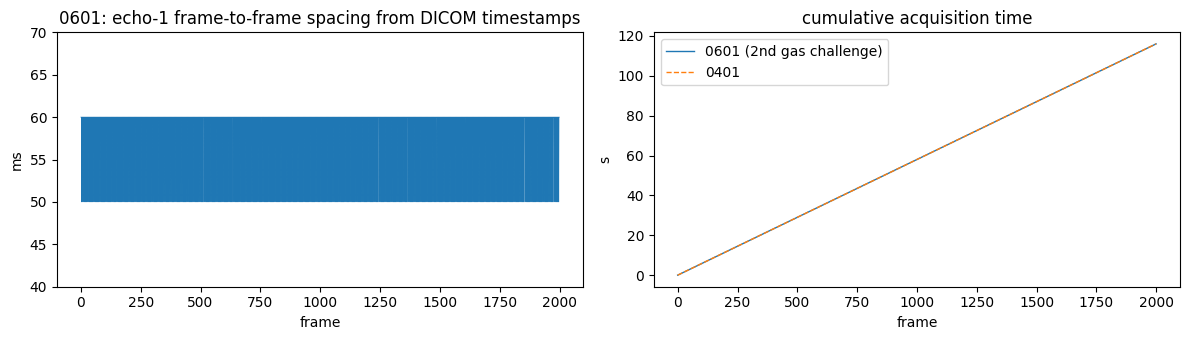

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
ax[0].plot(np.diff(t_0601) * 1000, lw=0.5)
ax[0].set(title='0601: echo-1 frame-to-frame spacing from DICOM timestamps', xlabel='frame', ylabel='ms', ylim=(40, 70))
ax[1].plot(t_0601, lw=1, label='0601 (2nd gas challenge)')
ax[1].plot(t_0401, lw=1, ls='--', label='0401')
ax[1].set(title='cumulative acquisition time', xlabel='frame', ylabel='s'); ax[1].legend()
plt.tight_layout(); plt.show()

## 2. Load image data

In [4]:
fast_e1 = load_series(os.path.join(ROOT, '0601_reg', 'reg', 'IM-01-01-*.hdr'))
fast_e2 = load_series(os.path.join(ROOT, '0601_reg', 'reg', 'IM-01-02-*.hdr'))
slow_e1 = {sl: load_series(os.path.join(ROOT, 'TV3_20220208', 'reg', f'IM-0{sl}-01-*.hdr')) for sl in range(1, 6)}
slow_e2 = {sl: load_series(os.path.join(ROOT, 'TV3_20220208', 'reg', f'IM-0{sl}-02-*.hdr')) for sl in range(1, 6)}
print('fast  echo1/echo2:', fast_e1.shape, fast_e2.shape, ' -> %.1f s of data' % (fast_e1.shape[0] * FAST_DT))
print('slow  echo1 per slice:', {k: v.shape for k, v in slow_e1.items()}, ' -> %.1f s of data' % (340 * SLOW_DT))

# Raw (unregistered) DICOM pixel data of both fast sessions, for a session-to-session comparison
def load_dicom_dynamics(path):
    ds = pydicom.dcmread(path, force=True)
    px = ds.pixel_array.astype(np.float32)          # (4000, 96, 96), echo1/echo2 interleaved
    return px[0::2], px[1::2]                        # same orientation as the registered Analyze files after rot90? -> checked below
raw0401_e1, raw0401_e2 = load_dicom_dynamics(os.path.join(ROOT, '0401', 'IM_0012'))
raw0601_e1, raw0601_e2 = load_dicom_dynamics(os.path.join(ROOT, '0601', 'IM_0010'))
print('raw DICOM dynamics:', raw0401_e1.shape, raw0601_e1.shape)
print('correlation raw-0601 frame0 vs registered frame0 (rot90):', np.corrcoef(raw0601_e1[0].ravel(), fast_e1[0].ravel())[0, 1].round(4))

fast  echo1/echo2: (2000, 96, 96) (2000, 96, 96)  -> 116.0 s of data
slow  echo1 per slice: {1: (340, 96, 96), 2: (340, 96, 96), 3: (340, 96, 96), 4: (340, 96, 96), 5: (340, 96, 96)}  -> 523.6 s of data


raw DICOM dynamics: (2000, 96, 96) (2000, 96, 96)
correlation raw-0601 frame0 vs registered frame0 (rot90): 0.9979


## 3. Lung mask

Simple automatic mask: body = Otsu threshold on the time-averaged image; lung = dark pixels inside the eroded body, keep the two largest components whose centre lies in the upper two thirds of the image (this drops stomach / bowel gas under the diaphragm). It is coarse, it includes some vessels, but it is the same procedure for every dataset so the curves are comparable.

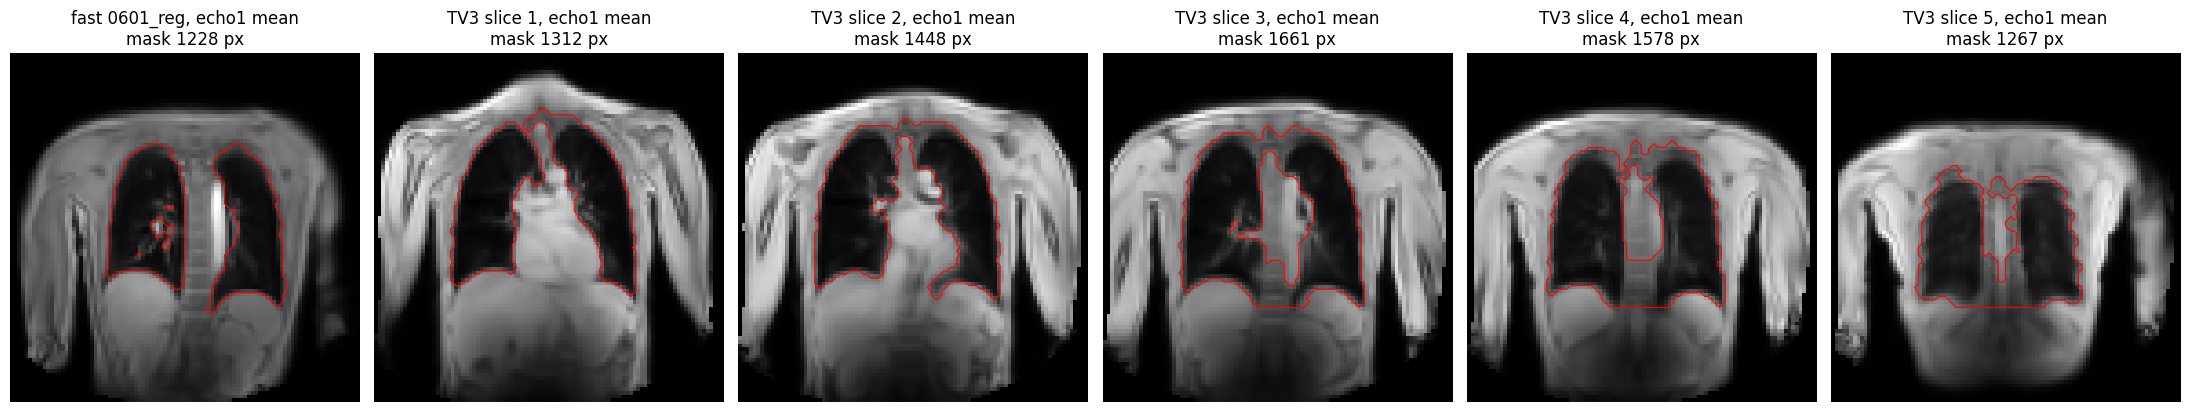

In [5]:
def lung_mask(mean_img, max_centroid_row=62, max_row=None):
    # max_row: ignore everything below this image row (cuts stomach/bowel gas under the diaphragm)
    body = mean_img > threshold_otsu(mean_img) * 0.5
    body = ndi.binary_fill_holes(ndi.binary_closing(body, iterations=2))
    lab, n = ndi.label(body)
    body = lab == (np.argmax(ndi.sum(body, lab, range(1, n + 1))) + 1)
    body = ndi.binary_fill_holes(body)
    thr = threshold_otsu(mean_img[body])
    dark = ndi.binary_erosion(body, iterations=3) & (mean_img < thr)
    if max_row is not None:
        dark[max_row:, :] = False
    dark = ndi.binary_opening(dark, iterations=1)
    lab, n = ndi.label(dark)
    sizes = ndi.sum(dark, lab, range(1, n + 1))
    centroids = ndi.center_of_mass(dark, lab, range(1, n + 1))
    cand = [(s, i) for i, (s, c) in enumerate(zip(sizes, centroids)) if c[0] < max_centroid_row]
    cand.sort(reverse=True)
    mask = np.zeros_like(dark)
    for s, i in cand[:2]:
        if s > 0.15 * cand[0][0]:
            mask |= lab == (i + 1)
    return mask

mask_fast = lung_mask(fast_e1.mean(0))
mask_raw0401 = lung_mask(raw0401_e1.mean(0))
mask_raw0601 = lung_mask(raw0601_e1.mean(0))
mask_slow = {sl: lung_mask(slow_e1[sl].mean(0), max_row=70) for sl in range(1, 6)}   # TV3 subject: diaphragm at ~row 70

fig, ax = plt.subplots(1, 6, figsize=(22, 4))
ax[0].imshow(fast_e1.mean(0), cmap='gray'); ax[0].contour(mask_fast, colors='r', linewidths=0.8)
ax[0].set_title(f'fast 0601_reg, echo1 mean\nmask {mask_fast.sum()} px')
for i, sl in enumerate(range(1, 6)):
    ax[i + 1].imshow(slow_e1[sl].mean(0), cmap='gray'); ax[i + 1].contour(mask_slow[sl], colors='r', linewidths=0.8)
    ax[i + 1].set_title(f'TV3 slice {sl}, echo1 mean\nmask {mask_slow[sl].sum()} px')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 4. Fast scan (58 ms): mean lung intensity over time

Three curves per echo: raw, 5 s moving average (removes breathing), and the echo ratio `log(S_TE1 / S_TE2)`, which is proportional to R2* and is insensitive to the density change caused by breathing. Oxygen should make the moving average drop by several percent and the echo ratio rise.

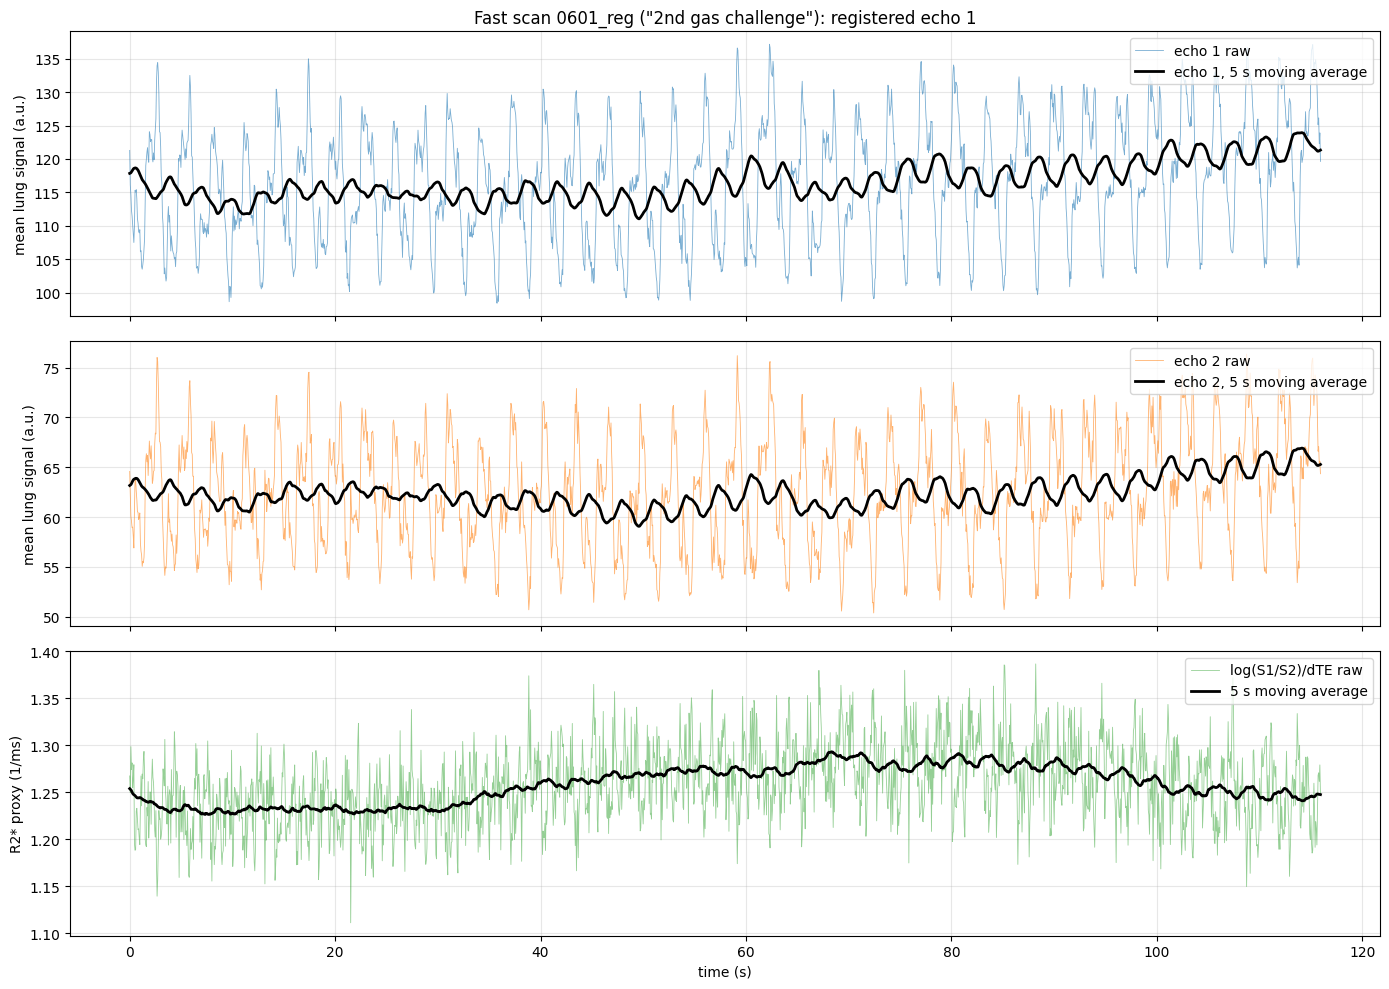

echo-1 smoothed: first 10 s = 114.1, last 10 s = 121.0, min = 111.0 at t = 49.6 s, max = 123.8 at t = 113.4 s
relative change first->last 10 s: 6.10 %


In [6]:
def moving_average(x, win):
    # edge-padded running mean (no zero-padding artefacts at the ends)
    return ndi.uniform_filter1d(x, win, mode='nearest')

t_fast = np.arange(fast_e1.shape[0]) * FAST_DT
c1 = fast_e1[:, mask_fast].mean(1)
c2 = fast_e2[:, mask_fast].mean(1)
win = int(round(5.0 / FAST_DT))   # 5 s window
c1s, c2s = moving_average(c1, win), moving_average(c2, win)
r2star_proxy = np.log(c1 / c2) / (1.2071 - 0.7099)   # 1/ms

fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
ax[0].plot(t_fast, c1, lw=0.6, alpha=0.6, label='echo 1 raw')
ax[0].plot(t_fast, c1s, lw=2, color='k', label='echo 1, 5 s moving average')
ax[0].set_ylabel('mean lung signal (a.u.)'); ax[0].legend(loc='upper right')
ax[0].set_title('Fast scan 0601_reg ("2nd gas challenge"): registered echo 1')
ax[1].plot(t_fast, c2, lw=0.6, alpha=0.6, color='tab:orange', label='echo 2 raw')
ax[1].plot(t_fast, c2s, lw=2, color='k', label='echo 2, 5 s moving average')
ax[1].set_ylabel('mean lung signal (a.u.)'); ax[1].legend(loc='upper right')
ax[2].plot(t_fast, r2star_proxy, lw=0.6, alpha=0.5, color='tab:green', label='log(S1/S2)/dTE raw')
ax[2].plot(t_fast, moving_average(r2star_proxy, win), lw=2, color='k', label='5 s moving average')
ax[2].set_ylabel('R2* proxy (1/ms)'); ax[2].set_xlabel('time (s)'); ax[2].legend(loc='upper right')
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

edge = win // 2
print('echo-1 smoothed: first 10 s = %.1f, last 10 s = %.1f, min = %.1f at t = %.1f s, max = %.1f at t = %.1f s' % (
    c1s[edge:edge + 170].mean(), c1s[-edge - 170:-edge].mean(),
    c1s[edge:-edge].min(), t_fast[edge:-edge][c1s[edge:-edge].argmin()],
    c1s[edge:-edge].max(), t_fast[edge:-edge][c1s[edge:-edge].argmax()]))
print('relative change first->last 10 s: %.2f %%' % ((c1s[-edge - 170:-edge].mean() / c1s[edge:edge + 170].mean() - 1) * 100))

### Zoom: what 1.54 s sampling misses

Breathing is the dominant signal change in the fast scan. The spectrum gives the breathing rate; the overlay shows the same 30 s sampled every 1.54 s (the clinical protocol).

dominant breathing frequency: 0.328 Hz  -> period 3.05 s  -> 19.7 breaths/min
Nyquist frequency of the 1.54 s protocol: 0.325 Hz


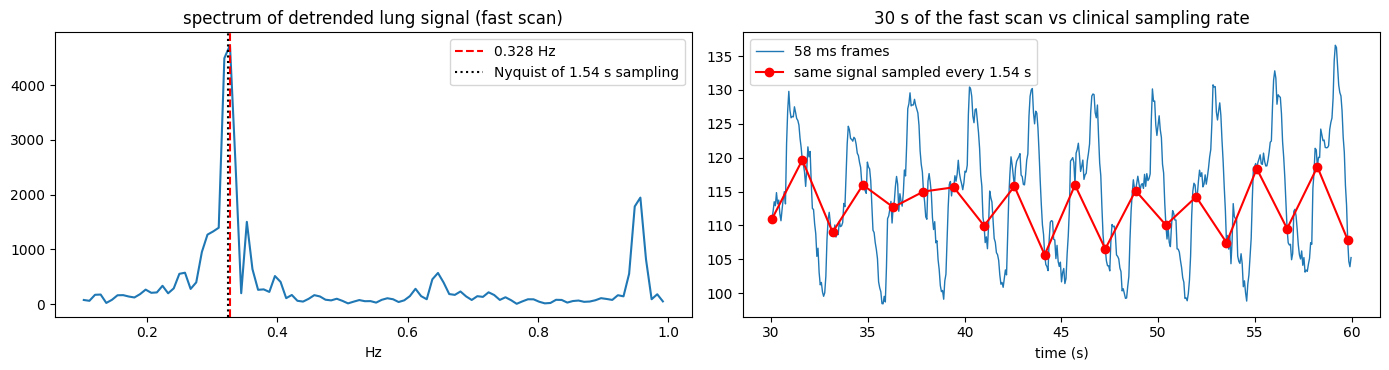

In [7]:
# breathing rate from the spectrum of the detrended echo-1 curve
x = c1 - c1s
freqs = np.fft.rfftfreq(len(x), FAST_DT)
spec = np.abs(np.fft.rfft(x * np.hanning(len(x))))
band = (freqs > 0.1) & (freqs < 1.0)
f_breath = freqs[band][spec[band].argmax()]
print('dominant breathing frequency: %.3f Hz  -> period %.2f s  -> %.1f breaths/min' % (f_breath, 1 / f_breath, 60 * f_breath))
print('Nyquist frequency of the 1.54 s protocol: %.3f Hz' % (0.5 / SLOW_DT))

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].plot(freqs[band], spec[band]); ax[0].axvline(f_breath, color='r', ls='--', label=f'{f_breath:.3f} Hz')
ax[0].axvline(0.5 / SLOW_DT, color='k', ls=':', label='Nyquist of 1.54 s sampling'); ax[0].legend()
ax[0].set(title='spectrum of detrended lung signal (fast scan)', xlabel='Hz')
sel = (t_fast >= 30) & (t_fast < 60)
ax[1].plot(t_fast[sel], c1[sel], lw=1, label='58 ms frames')
step = int(round(SLOW_DT / FAST_DT))
ax[1].plot(t_fast[sel][::step], c1[sel][::step], 'o-', color='r', label='same signal sampled every 1.54 s')
ax[1].set(title='30 s of the fast scan vs clinical sampling rate', xlabel='time (s)'); ax[1].legend()
plt.tight_layout(); plt.show()

### Session comparison: 0401 ("2D AICS3") vs 0601 ("2D AICS3 2nd gas challenge")

Both fast sessions are the same subject, same slice position, 10 minutes apart. If one was acquired on air and the other on oxygen, or if a gas switch happened during one of them, the absolute level or the slow trend should differ. Unregistered DICOM data, own mask per session.

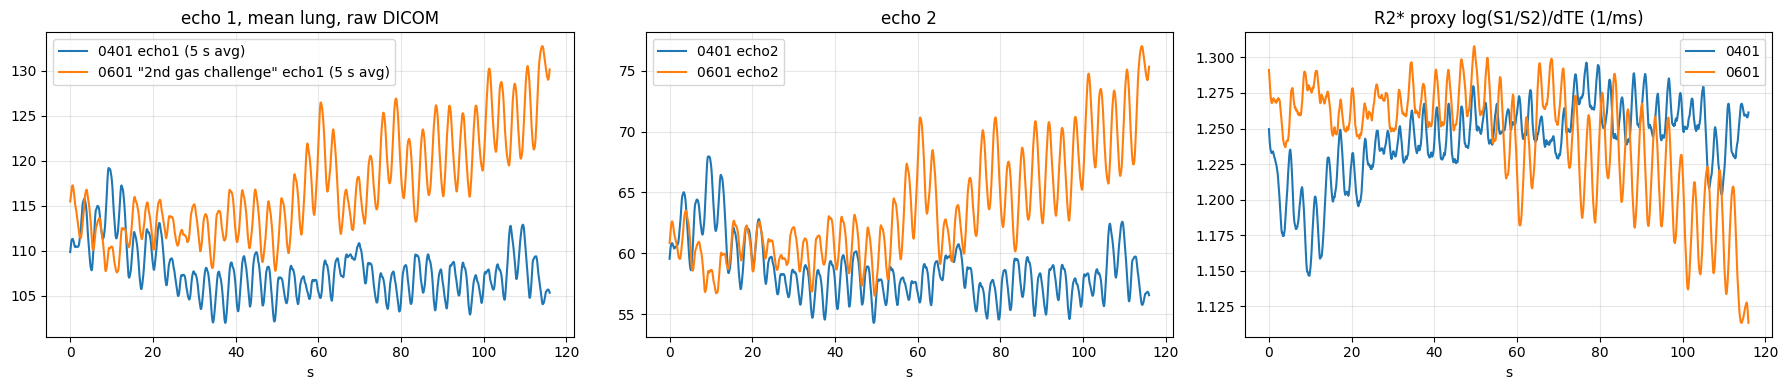

,session,mask px,echo1 mean (10-110 s),echo2 mean (10-110 s),R2* proxy mean (1/ms),echo1 change first->last 10 s (%)
0,0401,1282,107.388069,58.269363,1.244712,-4.395849
1,0601 (2nd gas challenge),1208,116.842049,63.505463,1.244095,12.181067


In [8]:
def session_curves(e1, e2, m):
    a, b = e1[:, m].mean(1), e2[:, m].mean(1)
    return a, b, moving_average(a, win), moving_average(b, win)

a1, b1, a1s, b1s = session_curves(raw0401_e1, raw0401_e2, mask_raw0401)
a2, b2, a2s, b2s = session_curves(raw0601_e1, raw0601_e2, mask_raw0601)
t = np.arange(2000) * FAST_DT
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(t, a1s, label='0401 echo1 (5 s avg)'); ax[0].plot(t, a2s, label='0601 "2nd gas challenge" echo1 (5 s avg)')
ax[0].set(title='echo 1, mean lung, raw DICOM', xlabel='s'); ax[0].legend()
ax[1].plot(t, b1s, label='0401 echo2'); ax[1].plot(t, b2s, label='0601 echo2'); ax[1].set(title='echo 2', xlabel='s'); ax[1].legend()
ax[2].plot(t, moving_average(np.log(a1 / b1), win) / 0.4972, label='0401'); ax[2].plot(t, moving_average(np.log(a2 / b2), win) / 0.4972, label='0601')
ax[2].set(title='R2* proxy log(S1/S2)/dTE (1/ms)', xlabel='s'); ax[2].legend()
for a in ax: a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

summary = pd.DataFrame({
    'session': ['0401', '0601 (2nd gas challenge)'],
    'mask px': [mask_raw0401.sum(), mask_raw0601.sum()],
    'echo1 mean (10-110 s)': [a1s[170:1900].mean(), a2s[170:1900].mean()],
    'echo2 mean (10-110 s)': [b1s[170:1900].mean(), b2s[170:1900].mean()],
    'R2* proxy mean (1/ms)': [(np.log(a1 / b1) / 0.4972)[170:1900].mean(), (np.log(a2 / b2) / 0.4972)[170:1900].mean()],
    'echo1 change first->last 10 s (%)': [(a1s[-213:-43].mean() / a1s[43:213].mean() - 1) * 100, (a2s[-213:-43].mean() / a2s[43:213].mean() - 1) * 100],
})
summary

## 5. Clinical-protocol scan TV3_20220208 (1.54 s): mean lung intensity over time

Protocol from Kim et al. 2024: dynamics 1-60 medical air, 61-210 100% O2, 211-340 air. Curves are normalised to the air baseline (frames 10-60). Expect a negative enhancement during O2 (T2* shortening) and recovery afterwards.

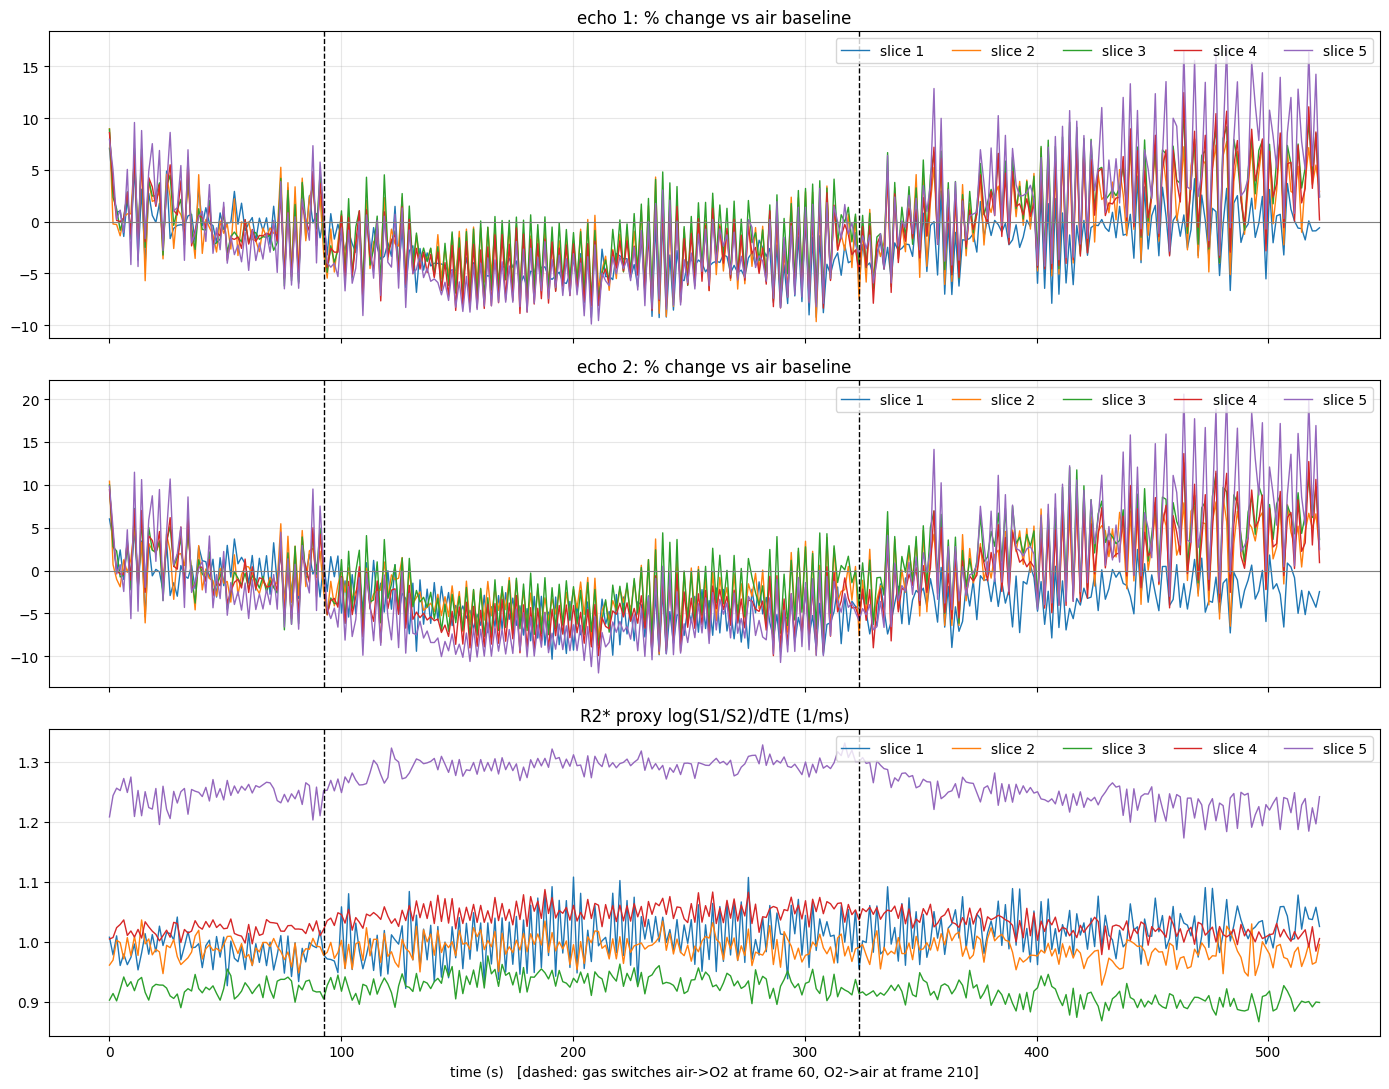

,slice,mask px,PSE echo1 (%),PSE echo2 (%),R2* air (1/ms),R2* O2 (1/ms),dR2* (1/ms),echo1 end vs baseline (%)
0,1,1312,-4.617,-5.919,0.980,1.015,0.035,-0.301
1,2,1448,-3.277,-3.631,0.987,0.995,0.008,3.181
2,3,1661,-2.594,-3.309,0.924,0.937,0.013,4.588
3,4,1578,-3.838,-5.352,1.022,1.052,0.031,4.290
4,5,1267,-4.282,-6.751,1.249,1.296,0.047,7.735


In [9]:
t_slow = np.arange(340) * SLOW_DT
fig, ax = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
rows = []
for sl in range(1, 6):
    m = mask_slow[sl]
    s1 = slow_e1[sl][:, m].mean(1); s2 = slow_e2[sl][:, m].mean(1)
    base1, base2 = s1[9:60].mean(), s2[9:60].mean()
    ax[0].plot(t_slow, 100 * (s1 / base1 - 1), lw=1, label=f'slice {sl}')
    ax[1].plot(t_slow, 100 * (s2 / base2 - 1), lw=1, label=f'slice {sl}')
    r2 = np.log(s1 / s2) / 0.4972
    ax[2].plot(t_slow, r2, lw=1, label=f'slice {sl}')
    rows.append({'slice': sl, 'mask px': int(m.sum()),
                 'PSE echo1 (%)': 100 * (s1[119:180].mean() / base1 - 1),
                 'PSE echo2 (%)': 100 * (s2[119:180].mean() / base2 - 1),
                 'R2* air (1/ms)': r2[29:60].mean(), 'R2* O2 (1/ms)': r2[119:180].mean(),
                 'dR2* (1/ms)': r2[119:180].mean() - r2[29:60].mean(),
                 'echo1 end vs baseline (%)': 100 * (s1[299:].mean() / base1 - 1)})
for a, ttl in zip(ax, ['echo 1: % change vs air baseline', 'echo 2: % change vs air baseline', 'R2* proxy log(S1/S2)/dTE (1/ms)']):
    for g in GAS_SWITCH_SLOW:
        a.axvline(g * SLOW_DT, color='k', ls='--', lw=1)
    a.set_title(ttl); a.grid(alpha=0.3); a.legend(loc='upper right', ncol=5)
ax[0].axhline(0, color='gray', lw=0.8); ax[1].axhline(0, color='gray', lw=0.8)
ax[2].set_xlabel('time (s)   [dashed: gas switches air->O2 at frame 60, O2->air at frame 210]')
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(3)

### Pixel-wise PSE map (slice with the clearest response)

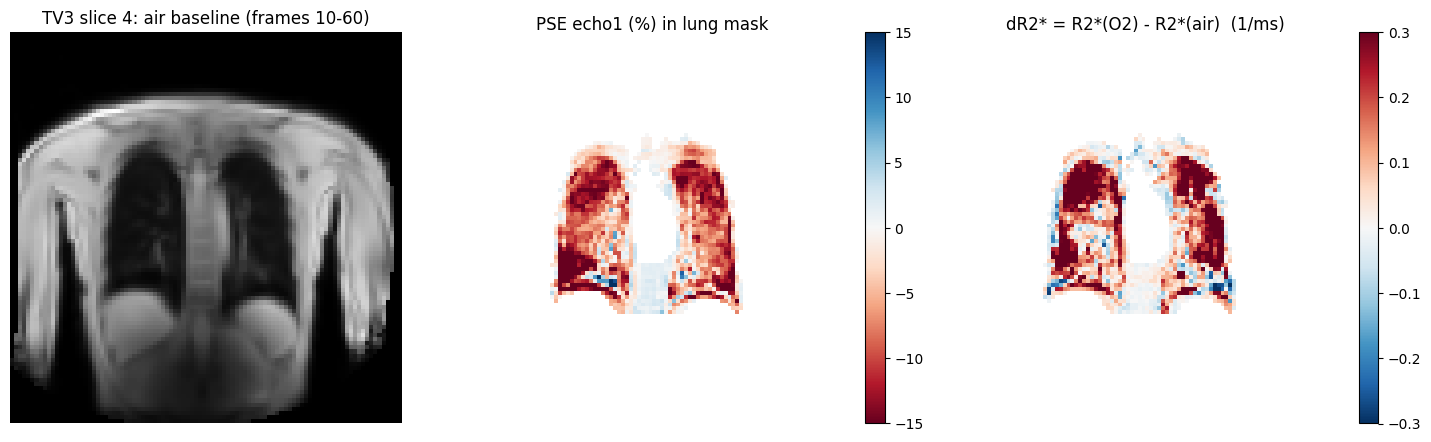

In [10]:
sl = 4
m = mask_slow[sl]
base = slow_e1[sl][9:60].mean(0); hyper = slow_e1[sl][119:180].mean(0)
pse = 100 * (hyper - base) / np.maximum(base, 1)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
ax[0].imshow(base, cmap='gray'); ax[0].set_title(f'TV3 slice {sl}: air baseline (frames 10-60)')
im = ax[1].imshow(np.where(m, pse, np.nan), cmap='RdBu', vmin=-15, vmax=15); ax[1].set_title('PSE echo1 (%) in lung mask'); plt.colorbar(im, ax=ax[1])
r2_base = np.log(np.maximum(slow_e1[sl][29:60].mean(0), 1) / np.maximum(slow_e2[sl][29:60].mean(0), 1)) / 0.4972
r2_hyp = np.log(np.maximum(slow_e1[sl][119:180].mean(0), 1) / np.maximum(slow_e2[sl][119:180].mean(0), 1)) / 0.4972
im = ax[2].imshow(np.where(m, r2_hyp - r2_base, np.nan), cmap='RdBu_r', vmin=-0.3, vmax=0.3); ax[2].set_title('dR2* = R2*(O2) - R2*(air)  (1/ms)'); plt.colorbar(im, ax=ax[2])
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 6. Conclusions

**Fast scans (0401, 0601): what they are.** Philips MR 7700 at 3T, 8 Jan 2025, single coronal slice, dual-echo spoiled gradient echo with TE1 = 0.71 ms / TE2 = 1.21 ms (identical TEs to the London protocol in Kim et al. 2024), TR = 2.23 ms, flip angle 4 deg, 96x96 matrix, 4.69 mm pixels, 10 mm slice, Compressed SENSE x3 plus partial Fourier. 2000 dynamics in 117.75 s, so one frame every 58.9 ms (scanner timestamps are quantised to 10 ms, hence the 50/60 ms mix). Echo 1 and echo 2 of a dynamic share the same timestamp.

**Why 1.54 s vs 58 ms.** The clinical protocol needs 96 lines x TR 16 ms = 1.54 s per frame (6 slices are interleaved inside that time). The fast scan shortens TR 7x, acquires only ~1/4 of the lines (CSENSE x3 + partial Fourier) and images a single slice. It is the same sequence family, so the contrast is comparable, but the fast data are noisier and cover one slice.

**Gas phases.**
- *TV3_20220208 (1.54 s):* the protocol (frames 1-60 air, 61-210 O2, 211-340 air) is visible in the data: mean lung echo-1 signal drops by ~2-5% during O2 (echo 2 slightly more), the echo-ratio R2* proxy rises by ~0.01-0.035 /ms and the signal recovers after frame 210. Anterior slice 1 and slice 4 show it most clearly. The remaining frame-to-frame scatter (+-5%) is breathing, under-sampled.
- *0601_reg (58 ms, "2nd gas challenge"):* no step or exponential change consistent with a gas switch is visible. The 5 s running mean of echo 1 is flat for ~100 s and then drifts up ~6%, the R2* proxy changes by <0.05 /ms without a clear direction, and the 0401 session (no "gas challenge" label) has the same R2* proxy (1.244 vs 1.244 /ms). So within these two 2-minute scans we cannot tell air from oxygen from the images; the gas state has to come from the scan log (the series name suggests the scan was acquired *around* a gas challenge). For PSE/R2* evaluation of synthesised frames the fast scan is therefore only useful for breathing/motion, unless Mina confirms a switch time inside it.

**Breathing.** The fast scan resolves breathing cleanly: dominant frequency 0.33 Hz (period ~3.0 s, ~20 breaths/min), amplitude ~+-15% of the lung signal, far larger than the oxygen effect. The Nyquist frequency of the 1.54 s protocol is 0.325 Hz, i.e. this subject's breathing sits *exactly at* the limit of what the clinical protocol can represent. That is the strongest quantitative argument for the temporal upsampling project: at 1.54 s the breathing modulation is aliased into the slow oxygen curve rather than resolved.